# 02 — Modeling Bank Customer Churn + Retention Recommendations

Tasks:
- Train baseline + XGBoost churn models
- Evaluate with ROC, PR, Recall@K
- Compute banking-specific CLV
- Segment customers
- Recommend retention actions
- Export final recommendations CSV

In [21]:
# Imports & config

import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve
)

from sklearn.utils.class_weight import compute_class_weight

from xgboost import XGBClassifier

sns.set(style="whitegrid")

TARGET_COL = "Churn Flag"
PROCESSED_DIR = "processed_bank"

In [22]:
# Load processed train/val/test

train = pd.read_parquet(os.path.join(PROCESSED_DIR, "train.parquet"))
val   = pd.read_parquet(os.path.join(PROCESSED_DIR, "val.parquet"))
test  = pd.read_parquet(os.path.join(PROCESSED_DIR, "test.parquet"))

train.shape, val.shape, test.shape


((60000, 25), (20000, 25), (20000, 25))

In [23]:
# Check there are no object dtypes in features:

feature_cols = [c for c in train.columns if c != TARGET_COL]

print("Train dtypes:")
print(train[feature_cols].dtypes.value_counts())
print("Any object columns in features?",
      train[feature_cols].select_dtypes(include="object").columns.tolist())


Train dtypes:
bool       12
int64       7
float64     3
int32       2
Name: count, dtype: int64
Any object columns in features? []


In [24]:
# Helper metrics (Recall@K, Lift table, ROC/PR plotting)

def recall_at_k(y_true, y_scores, k=0.1):
    """
    Recall among the top k fraction of users sorted by predicted score (descending).
    Example: k=0.1 -> top 10% highest-risk customers.
    """
    y_true = np.asarray(y_true)
    y_scores = np.asarray(y_scores)

    n = len(y_true)
    cutoff = int(np.ceil(k * n))
    order = np.argsort(-y_scores)  # descending
    top_idx = order[:cutoff]

    return y_true[top_idx].sum() / y_true.sum()


def make_lift_table(y_true, y_scores, n_bins=10):
    """
    Build a simple lift table with deciles.
    """
    df = pd.DataFrame({"y_true": y_true, "score": y_scores})
    df = df.sort_values("score", ascending=False).reset_index(drop=True)
    df["bucket"] = pd.qcut(df.index, n_bins, labels=False)

    lift = df.groupby("bucket").agg(
        n=("y_true", "size"),
        events=("y_true", "sum"),
        score_mean=("score", "mean")
    )

    overall_rate = df["y_true"].mean()
    lift["rate"] = lift["events"] / lift["n"]
    lift["lift"] = lift["rate"] / overall_rate

    return lift, overall_rate


def plot_roc_pr(y_true, y_scores, title_prefix=""):
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    prec, rec, _ = precision_recall_curve(y_true, y_scores)

    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr)
    plt.plot([0,1], [0,1], "k--", alpha=0.5)
    plt.title(f"{title_prefix} ROC")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(5,4))
    plt.plot(rec, prec)
    plt.title(f"{title_prefix} Precision–Recall")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.grid(True)
    plt.show()


In [25]:
# Split features/targets

X_train, y_train = train[feature_cols], train[TARGET_COL]
X_val,   y_val   = val[feature_cols],   val[TARGET_COL]
X_test,  y_test  = test[feature_cols],  test[TARGET_COL]

X_train.shape, X_val.shape, X_test.shape


((60000, 24), (20000, 24), (20000, 24))

In [26]:
# Class weights for imbalance

classes = np.array([0, 1])
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.values
)
class_weight_dict = {cls: w for cls, w in zip(classes, class_weights)}
class_weight_dict


{0: 0.569432844886493, 1: 4.1006014215418265}

LogReg AUC (val):    0.9963011625798448
LogReg PR-AUC (val): 0.9748806729015573
LogReg AUC (test):   0.9965788086785828
LogReg PR-AUC (test): 0.9778780213216426
LogReg Recall@Top 5% (val): 0.410
LogReg Recall@Top 10% (val): 0.792
LogReg Recall@Top 20% (val): 1.000


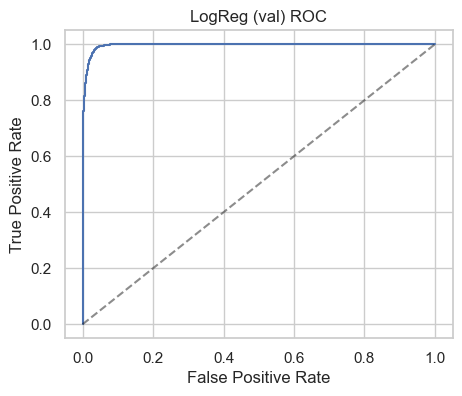

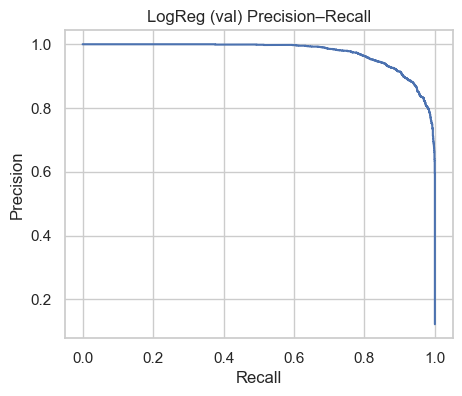

In [27]:
# Baseline model: Logistic Regression

logreg = LogisticRegression(
    max_iter=500,
    class_weight=class_weight_dict,
    n_jobs=-1
)

logreg.fit(X_train, y_train)

val_scores_lr  = logreg.predict_proba(X_val)[:, 1]
test_scores_lr = logreg.predict_proba(X_test)[:, 1]

print("LogReg AUC (val):   ", roc_auc_score(y_val, val_scores_lr))
print("LogReg PR-AUC (val):", average_precision_score(y_val, val_scores_lr))
print("LogReg AUC (test):  ", roc_auc_score(y_test, test_scores_lr))
print("LogReg PR-AUC (test):", average_precision_score(y_test, test_scores_lr))

for k in [0.05, 0.10, 0.20]:
    r = recall_at_k(y_val.values, val_scores_lr, k=k)
    print(f"LogReg Recall@Top {int(k*100)}% (val): {r:.3f}")


# Plot its ROC/PR

plot_roc_pr(y_val, val_scores_lr, title_prefix="LogReg (val)")


XGB AUC (val):    0.9996861698654125
XGB PR-AUC (val): 0.997831176653169
XGB AUC (test):   0.9998131505715718
XGB PR-AUC (test): 0.9986731283975931
XGB Recall@Top 5% (val): 0.410
XGB Recall@Top 10% (val): 0.820
XGB Recall@Top 20% (val): 1.000


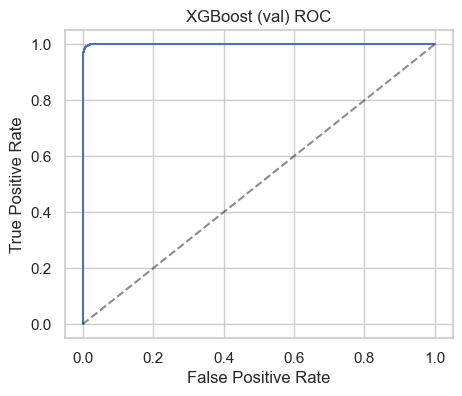

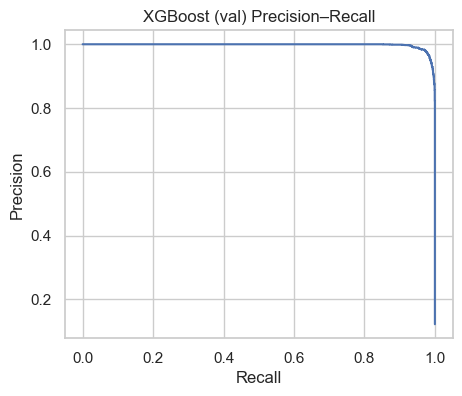

In [28]:
# XGBoost model (main model)

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=class_weight_dict[1] / class_weight_dict[0]  # handle imbalance
)

xgb.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

val_scores_xgb  = xgb.predict_proba(X_val)[:, 1]
test_scores_xgb = xgb.predict_proba(X_test)[:, 1]

print("XGB AUC (val):   ", roc_auc_score(y_val, val_scores_xgb))
print("XGB PR-AUC (val):", average_precision_score(y_val, val_scores_xgb))
print("XGB AUC (test):  ", roc_auc_score(y_test, test_scores_xgb))
print("XGB PR-AUC (test):", average_precision_score(y_test, test_scores_xgb))

for k in [0.05, 0.10, 0.20]:
    r = recall_at_k(y_val.values, val_scores_xgb, k=k)
    print(f"XGB Recall@Top {int(k*100)}% (val): {r:.3f}")


# Plot ROC/PR

plot_roc_pr(y_val, val_scores_xgb, title_prefix="XGBoost (val)")




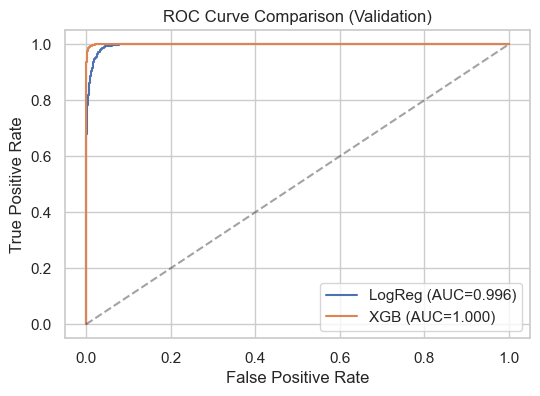

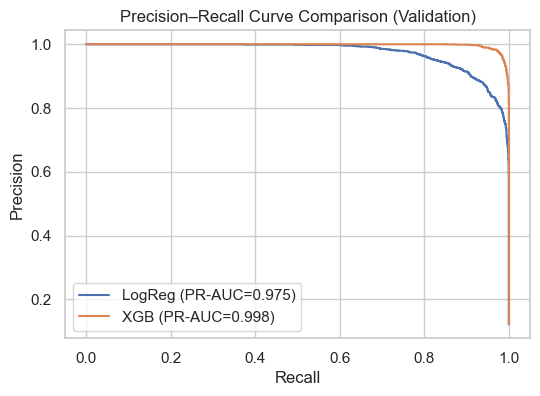

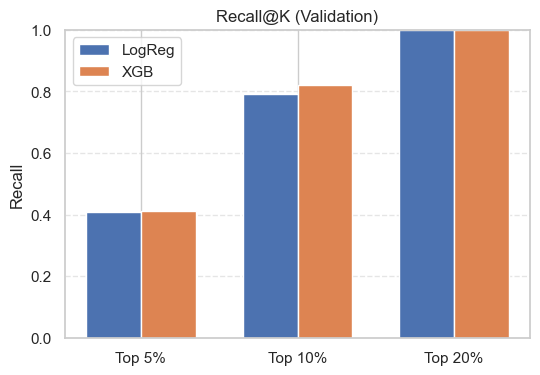

In [30]:
# Compare ROC, PR, and Recall@K visually

# Combined ROC
fpr_lr,  tpr_lr,  _ = roc_curve(y_val, val_scores_lr)
fpr_xgb, tpr_xgb, _ = roc_curve(y_val, val_scores_xgb)

plt.figure(figsize=(6,4))
plt.plot(fpr_lr, tpr_lr, label=f"LogReg (AUC={roc_auc_score(y_val, val_scores_lr):.3f})")
plt.plot(fpr_xgb, tpr_xgb, label=f"XGB (AUC={roc_auc_score(y_val, val_scores_xgb):.3f})")
plt.plot([0,1], [0,1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison (Validation)")
plt.legend()
plt.grid(True)
plt.show()



# Combined PR
prec_lr,  rec_lr,  _ = precision_recall_curve(y_val, val_scores_lr)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_val, val_scores_xgb)

plt.figure(figsize=(6,4))
plt.plot(rec_lr,  prec_lr,  label=f"LogReg (PR-AUC={average_precision_score(y_val, val_scores_lr):.3f})")
plt.plot(rec_xgb, prec_xgb, label=f"XGB (PR-AUC={average_precision_score(y_val, val_scores_xgb):.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison (Validation)")
plt.legend()
plt.grid(True)
plt.show()



# Recall@K bar chart
Ks = [0.05, 0.10, 0.20]
recall_lr  = [recall_at_k(y_val.values, val_scores_lr,  k) for k in Ks]
recall_xgb = [recall_at_k(y_val.values, val_scores_xgb, k) for k in Ks]

x = np.arange(len(Ks))
width = 0.35

plt.figure(figsize=(6,4))
plt.bar(x - width/2, recall_lr,  width, label="LogReg")
plt.bar(x + width/2, recall_xgb, width, label="XGB")
plt.xticks(x, [f"Top {int(k*100)}%" for k in Ks])
plt.ylabel("Recall")
plt.title("Recall@K (Validation)")
plt.ylim(0, 1)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend()
plt.show()



In [33]:
# Lift table for XGBoost

lift_xgb, overall_rate = make_lift_table(y_val.values, val_scores_xgb, n_bins=10)
lift_xgb

,n,events,score_mean,rate,lift
bucket,,,,,
0,2000,2000,9.932256e-01,1.000,8.203445
1,2000,438,4.030795e-01,0.219,1.796555
2,2000,0,3.057382e-03,0.000,0.000000
3,2000,0,1.816838e-04,0.000,0.000000
4,2000,0,5.036024e-05,0.000,0.000000
5,2000,0,1.965506e-05,0.000,0.000000
6,2000,0,8.052934e-06,0.000,0.000000
7,2000,0,3.203895e-06,0.000,0.000000
8,2000,0,1.131813e-06,0.000,0.000000


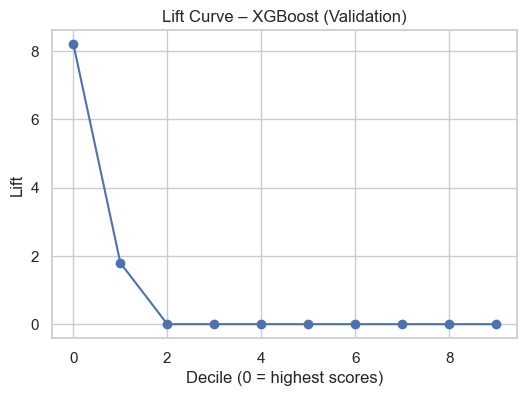

In [34]:
# plot lift curve

plt.figure(figsize=(6,4))
plt.plot(lift_xgb.index, lift_xgb["lift"], marker="o")
plt.xlabel("Decile (0 = highest scores)")
plt.ylabel("Lift")
plt.title("Lift Curve – XGBoost (Validation)")
plt.grid(True)
plt.show()

In [35]:
# Choose final model and compute scores for all data
# Choose XGB

final_model = xgb

train_scores = final_model.predict_proba(X_train)[:, 1]
val_scores   = val_scores_xgb
test_scores  = final_model.predict_proba(X_test)[:, 1]

train_with_scores = train.copy()
val_with_scores   = val.copy()
test_with_scores  = test.copy()

train_with_scores["churn_score"] = train_scores
val_with_scores["churn_score"]   = val_scores
test_with_scores["churn_score"]  = test_scores

df_scores = pd.concat(
    [train_with_scores, val_with_scores, test_with_scores],
    axis=0
).reset_index(drop=True)

df_scores[["churn_score", TARGET_COL]].head()


,churn_score,Churn Flag
0,9.963972e-01,1
1,4.526386e-05,0
2,8.974394e-07,0
3,2.908874e-06,0
4,1.336598e-07,0


In [36]:
# CLV estimation & expected lost value

df_scores["clv_est"] = (
    df_scores.get("Balance", 0)
    + 0.5 * df_scores.get("Outstanding Loans", 0)
    + 200 * df_scores.get("NumOfProducts", 0)
)

df_scores["expected_lost_value"] = df_scores["churn_score"] * df_scores["clv_est"]

df_scores[["churn_score", "clv_est", "expected_lost_value"]].describe()


,churn_score,clv_est,expected_lost_value
count,1.000000e+05,100000.00000,100000.000000
mean,1.377503e-01,138062.93511,5853.179497
std,3.255883e-01,72588.89508,15544.813318
min,3.042020e-08,925.42000,0.002366
25%,3.046403e-06,75591.23500,0.481808
50%,2.885362e-05,137966.05000,4.477073
75%,1.338044e-03,200516.52250,133.442721
max,9.999982e-01,275321.26000,127630.256522


In [37]:
# Segmentation (bank-specific)

def assign_segment(row, balance_median=None):
    if balance_median is None and "Balance" in df_scores.columns:
        balance_median = df_scores["Balance"].median()
    balance = row.get("Balance", 0)
    products = row.get("NumOfProducts", 0)
    complaints = row.get("NumOfComplaints", 0)
    tenure = row.get("Customer Tenure", 0)

    if balance > balance_median and products >= 3:
        return "affluent_multi_product"
    if complaints > 0:
        return "high_complaint_risk"
    if tenure < 6:
        return "new_customer"
    if products == 1:
        return "single_product_low_engagement"
    return "mass_market"

balance_median_train = df_scores.loc[df_scores.index.isin(train.index), "Balance"].median() \
    if "Balance" in df_scores.columns else None

df_scores["segment"] = df_scores.apply(assign_segment, axis=1, balance_median=balance_median_train)
df_scores["segment"].value_counts(normalize=True)


segment
mass_market                      0.41945
affluent_multi_product           0.29991
single_product_low_engagement    0.16504
new_customer                     0.11560
Name: proportion, dtype: float64

In [38]:
# Retention recommendation rules
# Targeting only the top 20% by churn_score

cutoff = df_scores["churn_score"].quantile(0.8)
cutoff


0.013246062397956903

In [39]:
def recommend_action(row, cutoff=cutoff):
    if row["churn_score"] < cutoff:
        return "no_action"

    seg = row["segment"]

    if seg == "affluent_multi_product":
        return "personal_banker_outreach_rate_offer"
    if seg == "high_complaint_risk":
        return "service_recovery_and_fee_refund"
    if seg == "new_customer":
        return "onboarding_support_and_welcome_offer"
    if seg == "single_product_low_engagement":
        return "cross_sell_bundle_offer"
    return "general_retention_email"

df_scores["recommended_action"] = df_scores.apply(recommend_action, axis=1)
df_scores["recommended_action"].value_counts(normalize=True)


recommended_action
no_action                               0.80000
general_retention_email                 0.11715
cross_sell_bundle_offer                 0.05002
onboarding_support_and_welcome_offer    0.03283
Name: proportion, dtype: float64

In [41]:
# Export final recommendation table

OUTPUT_DIR = "outputs_bank"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Try to carry over some kind of ID if it survived (if not, index will be your ID)
id_candidates = [c for c in df_scores.columns if "id" in c.lower() or "customer" in c.lower()]
id_cols = [c for c in id_candidates if c not in cols_to_drop] if "cols_to_drop" in globals() else id_candidates

base_cols = [
    "churn_score",
    "clv_est",
    "expected_lost_value",
    "segment",
    "recommended_action",
    TARGET_COL
]

extra_cols = [c for c in ["Balance", "NumOfProducts", "Customer Tenure", "NumOfComplaints"] if c in df_scores.columns]

export_cols = id_cols + base_cols + extra_cols
export_cols = list(dict.fromkeys(export_cols))  # remove duplicates while preserving order

df_recs = df_scores[export_cols].copy()

df_recs.sort_values("expected_lost_value", ascending=False).head(10)


,Customer Tenure,Customer Segment_Retail,Customer Segment_SME,churn_score,clv_est,expected_lost_value,segment,recommended_action,Churn Flag,Balance,NumOfProducts
8702,9,True,False,0.994516,128334.000,127630.256522,single_product_low_engagement,cross_sell_bundle_offer,1,104702.84,1
18809,22,True,False,0.990116,127583.570,126322.511203,single_product_low_engagement,cross_sell_bundle_offer,1,105274.24,1
35250,4,False,False,0.970375,127239.790,123470.258315,new_customer,onboarding_support_and_welcome_offer,1,106270.67,1
8156,16,False,False,0.946509,128952.200,122054.387594,single_product_low_engagement,cross_sell_bundle_offer,1,114069.80,1
44445,21,False,True,0.926462,131430.920,121765.814973,single_product_low_engagement,cross_sell_bundle_offer,1,114924.46,1
43091,7,True,False,0.996702,122145.615,121742.751521,single_product_low_engagement,cross_sell_bundle_offer,1,101394.52,1
27704,7,True,False,0.967054,125348.120,121218.461792,mass_market,general_retention_email,1,100345.23,2
13174,2,False,False,0.953292,126887.295,120960.667464,new_customer,onboarding_support_and_welcome_offer,1,101605.17,2
32336,13,False,True,0.959876,125178.625,120155.943038,mass_market,general_retention_email,1,100579.75,2
59480,18,False,False,0.938118,127269.865,119394.126033,single_product_low_engagement,cross_sell_bundle_offer,1,108399.29,1


In [42]:
output_path = os.path.join(OUTPUT_DIR, "bank_churn_recommendations.csv")
df_recs.to_csv(output_path, index=False)
print("Saved recommendations to:", output_path)

Saved recommendations to: outputs_bank\bank_churn_recommendations.csv


In [43]:
# Save the model (for Notebook 3 / inference)

os.makedirs("models", exist_ok=True)
model_path = "models/xgb_bank_churn.json"
xgb.save_model(model_path)
print("Saved XGBoost model to:", model_path)


Saved XGBoost model to: models/xgb_bank_churn.json
